In [1]:
import geopandas as gpd
import pandas as pd
from shapely import from_wkt

In [2]:
buildings = pd.read_csv("data/967_buildings_fixed.csv", engine="pyarrow")
buildings

,latitude,longitude,area_in_meters,confidence,geometry,full_plus_code
0,-36.794835,-73.037232,31.5948,0.8334,"POLYGON((-73.0371866084166 -36.7948252568355, ...",47M86X47+346P
1,-32.967680,-68.848503,28.2412,0.6516,"POLYGON((-68.8484604097925 -32.9676691232373, ...",47VH25J2+WHHQ
2,-36.977957,-72.096709,16.0656,0.7186,"POLYGON((-72.0966811967563 -36.9779444377915, ...",47M92WC3+R87M
3,-36.615942,-72.126127,60.4079,0.8680,"POLYGON((-72.1260603300031 -36.6159446703355, ...",47M99VMF+JGH9
4,-37.095119,-73.150454,64.9039,0.8197,"POLYGON((-73.1504011342381 -37.095087180879, -...",47J8WR3X+XR37
...,...,...,...,...,...,...
9564738,-37.478677,-73.334922,51.6419,0.7359,"POLYGON((-73.3348785230319 -37.4787069510247, ...",47J8GMC8+G2GW
9564739,-34.656695,-69.475944,9.1364,0.6805,"POLYGON((-69.475919761342 -34.6567008453253, -...",47QG8GVF+8JF9
9564740,-33.406000,-70.681176,39.3759,0.7239,"POLYGON((-70.6811602578338 -33.4059467155984, ...",47RFH8V9+JG43
9564741,-33.479767,-70.533263,57.8778,0.7740,"POLYGON((-70.5332612719794 -33.4798220677037, ...",47RFGFC8+3MX8


In [ ]:
blocks = gpd.read_file("data/2017/microdatos_manzana/Microdatos_Manzana.shp", encoding="latin1")
blocks.columns = blocks.columns.str.lower()

# the .dbf is UTF-8 but has a few corrupt bytes, so it's read as latin1 and each value re-decoded
def fix_encoding(s):
    try:
        return s.encode("latin1").decode("utf-8")
    except (UnicodeError, AttributeError):
        return s

name_cols = ["region", "provincia", "comuna", "nombre_dis"]
for c in name_cols:
    blocks[c] = blocks[c].map(fix_encoding)

# one block has garbage in provincia/comuna: take the names from the other blocks of its comuna
comuna_code = blocks.manzent.str[:-9]
for c in ["region", "provincia", "comuna"]:
    blocks[c] = blocks.groupby(comuna_code)[c].transform(lambda s: s.mode().iloc[0])

blocks = blocks.rename(columns={"manzent": "id_manzent"}).to_crs(4326)
blocks.id_manzent = blocks.id_manzent.astype(int)
blocks["tipo"] = "manzana"

# rural entities (caseríos, fundos, ...) are in a separate shapefile with no id_manzent:
# rebuild it from its parts (comuna + distrito + area + localidad + entidad) and append them
entities = gpd.read_file("data/2017/microdatos_manzana/Microdatos_Entidad.shp", encoding="latin1")
entities.columns = entities.columns.str.lower()
entities = entities.rename(columns={"nombre_com": "comuna"})
for c in ["region", "provincia", "comuna"]:
    entities[c] = entities[c].map(fix_encoding)
entities["id_manzent"] = (
    entities.cod_comuna.astype(int).astype(str)
    + entities.distrito.astype(int).map("{:02}".format)
    + entities["area"].astype(int).astype(str)  # ["area"]: .area is the geometric area
    + entities.codigo_loc.astype(int).map("{:03}".format)
    + entities.codigo_ent.astype(int).map("{:03}".format)
).astype(int)
entities["tipo"] = "entidad"

# blocks + entities
blocks = pd.concat(
    [blocks, entities[blocks.columns.intersection(entities.columns)].to_crs(4326)],
    ignore_index=True,
)
blocks = blocks[blocks.provincia == "CONCEPCIÓN"]
# blocks = blocks[blocks.comuna == "CONCEPCIÓN"]
blocks

,cut,region,provincia,comuna,nombre_dis,codigo_dis,id_manzent,zona_censa,manzana,total_pers,...,viv_piso_t,viv_materi,viv_mate_1,viv_mate_2,viv_agua_r,viv_agua_p,viv_agua_c,viv_agua_1,geometry,tipo
138477,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26.0,8101261003001,3.0,1.0,67,...,0,13,3,4,20,0,0,0,"POLYGON ((-73.06065 -36.83835, -73.06067 -36.8...",manzana
138478,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26.0,8101261003005,3.0,5.0,0,...,0,0,0,0,0,0,0,0,"POLYGON ((-73.05748 -36.83809, -73.05799 -36.8...",manzana
138479,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26.0,8101261002006,2.0,6.0,53,...,0,8,10,0,19,0,0,0,"POLYGON ((-73.05655 -36.83784, -73.05734 -36.8...",manzana
138480,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LO PEQUÉN,32.0,8101321004027,4.0,27.0,131,...,0,31,4,4,39,0,0,0,"POLYGON ((-73.00417 -36.83844, -73.00419 -36.8...",manzana
138481,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LA TOMA,16.0,8101161003010,3.0,10.0,410,...,0,111,16,0,128,0,0,0,"POLYGON ((-73.04733 -36.79638, -73.04652 -36.7...",manzana
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179245,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,LOTA,NaN,NaN,8106062001006,NaN,NaN,30,...,0,10,5,0,1,11,0,3,"POLYGON ((-73.16649 -37.14432, -73.16632 -37.1...",entidad
179246,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,LOTA,NaN,NaN,8106062901901,NaN,NaN,28,...,0,8,4,0,0,0,0,11,"MULTIPOLYGON (((-73.16862 -37.14419, -73.16928...",entidad
179423,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,SAN PEDRO DE LA PAZ,NaN,NaN,8108062002002,NaN,NaN,45,...,0,14,0,0,0,0,0,14,"POLYGON ((-73.04914 -36.92719, -73.04921 -36.9...",entidad
179424,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,SAN PEDRO DE LA PAZ,NaN,NaN,8108052001001,NaN,NaN,10,...,0,3,2,0,0,1,0,4,"POLYGON ((-73.10324 -36.86502, -73.10298 -36.8...",entidad


In [4]:
# keep buildings whose centroid (latitude/longitude) falls inside a block
points = gpd.GeoDataFrame(
    buildings[[]],
    geometry=gpd.points_from_xy(buildings.longitude, buildings.latitude),
    crs=4326,
)
joined = gpd.sjoin(points, blocks[["id_manzent", *name_cols, "geometry"]], how="inner", predicate="within")
joined = joined[~joined.index.duplicated()]  # overlapping blocks -> keep one match

buildings = buildings.loc[joined.index].join(joined[["id_manzent", *name_cols]])
buildings = gpd.GeoDataFrame(buildings, geometry=from_wkt(buildings.geometry), crs=4326)
buildings

,latitude,longitude,area_in_meters,confidence,geometry,full_plus_code,id_manzent,region,provincia,comuna,nombre_dis
0,-36.794835,-73.037232,31.5948,0.8334,"POLYGON ((-73.03719 -36.79483, -73.03722 -36.7...",47M86X47+346P,8101161003016,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LA TOMA
4,-37.095119,-73.150454,64.9039,0.8197,"POLYGON ((-73.1504 -37.09509, -73.15047 -37.09...",47J8WR3X+XR37,8106031001502,REGIÓN DEL BIOBÍO,CONCEPCIÓN,LOTA,LOTA BAJO
8,-36.897536,-72.730595,22.5711,0.7713,"POLYGON ((-72.73056 -36.89752, -72.73061 -36.8...",47M94729+XQJH,8104032053150,REGIÓN DEL BIOBÍO,CONCEPCIÓN,FLORIDA,NaN
17,-37.097080,-72.973459,24.2077,0.6660,"POLYGON ((-72.97343 -37.09706, -72.97349 -37.0...",47J9W23G+5J7V,8105092901901,REGIÓN DEL BIOBÍO,CONCEPCIÓN,HUALQUI,NaN
23,-37.013586,-73.156410,62.2451,0.8616,"POLYGON ((-73.15636 -37.01362, -73.15637 -37.0...",47J8XRPV+HC8H,8102021002003,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CORONEL,VILLA MORA
...,...,...,...,...,...,...,...,...,...,...,...
9564564,-37.104292,-72.951889,14.9993,0.8093,"POLYGON ((-72.95186 -37.1043, -72.95188 -37.10...",47J9V2WX+76Q8,8105092901901,REGIÓN DEL BIOBÍO,CONCEPCIÓN,HUALQUI,NaN
9564587,-37.094389,-73.143955,14.4798,0.7265,"POLYGON ((-73.14392 -37.09438, -73.14395 -37.0...",47J8WV44+6CVF,8106041002075,REGIÓN DEL BIOBÍO,CONCEPCIÓN,LOTA,CEMENTERIO
9564595,-37.173596,-72.942227,54.9633,0.8142,"POLYGON ((-72.94225 -37.17366, -72.94216 -37.1...",47J9R3G5+H464,8109011002024,REGIÓN DEL BIOBÍO,CONCEPCIÓN,SANTA JUANA,SANTA JUANA
9564617,-36.770650,-73.070076,61.6159,0.7689,"POLYGON ((-73.07005 -36.77071, -73.07004 -36.7...",47M86WHH+PXV4,8110141006504,REGIÓN DEL BIOBÍO,CONCEPCIÓN,TALCAHUANO,CARRIEL


In [5]:
import shapely

RATIO = 0.45        # concave_hull ratio: 0 = most concave, 1 = convex hull
CLUSTER_GAP = 5   # metres: buildings closer than this belong to the same cluster

# work in a metric CRS so distances are in metres
metric_crs = buildings.estimate_utm_crs()
buildings_m = buildings.to_crs(metric_crs)[["id_manzent", "geometry"]]

# cluster buildings within each block: grow each building by half the gap,
# merge what touches and give each merged blob a cluster id
blobs = (
    buildings_m.assign(geometry=buildings_m.buffer(CLUSTER_GAP / 2))
    .dissolve("id_manzent")
    .explode(index_parts=False)
    .reset_index()
)
blobs["cluster"] = range(len(blobs))
in_blob = gpd.sjoin(
    buildings_m.assign(geometry=buildings_m.representative_point()),
    blobs, predicate="within",
)
in_blob = in_blob[in_blob.id_manzent_left == in_blob.id_manzent_right]
buildings_m["cluster"] = in_blob.cluster[~in_blob.index.duplicated()]

# one concave hull per cluster, then merge the hulls of each block
cluster_unions = buildings_m.groupby("cluster").agg(
    id_manzent=("id_manzent", "first"),
    geometry=("geometry", shapely.union_all),
)
cluster_hulls = gpd.GeoSeries(
    shapely.concave_hull(cluster_unions.geometry.values, ratio=RATIO, allow_holes=False),
    index=cluster_unions.index,
    crs=metric_crs,
)
hulls = cluster_hulls.groupby(cluster_unions.id_manzent).apply(shapely.union_all)
hulls = gpd.GeoSeries(hulls, crs=metric_crs)

# keep the hull inside its original block (building footprints can poke out of it)
block_geoms = blocks.set_index("id_manzent").geometry.to_crs(metric_crs).loc[hulls.index]
hulls = hulls.intersection(block_geoms, align=True)

# drop tiny hull parts, but only in big blocks and only when they're tiny next to
# the block's largest part (small blocks like the square city blocks stay as they are)
MIN_BLOCK_AREA = 20_000   # m²: only clean blocks bigger than this (square city blocks are ~10-14k)
MIN_PART_RATIO = 0.05     # drop parts smaller than this fraction of the block's largest part

parts = hulls.rename("geometry").reset_index().explode(index_parts=False)
parts = parts[parts.geometry.geom_type == "Polygon"]
part_area = parts.geometry.area
largest = part_area.groupby(parts.id_manzent).transform("max")
big_block = parts.id_manzent.map(block_geoms.area) > MIN_BLOCK_AREA
parts = parts[~(big_block & (part_area < MIN_PART_RATIO * largest))]
hulls = gpd.GeoSeries(
    parts.groupby("id_manzent").geometry.apply(shapely.union_all), crs=metric_crs
)

building_blocks = (
    blocks.drop(columns="geometry")
    .merge(hulls.rename("geometry").reset_index(), on="id_manzent")
    .pipe(gpd.GeoDataFrame, geometry="geometry", crs=metric_crs)
    .to_crs(4326)
)
building_blocks

,cut,region,provincia,comuna,nombre_dis,codigo_dis,id_manzent,zona_censa,manzana,total_pers,...,viv_piso_t,viv_materi,viv_mate_1,viv_mate_2,viv_agua_r,viv_agua_p,viv_agua_c,viv_agua_1,tipo,geometry
0,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26.0,8101261003001,3.0,1.0,67,...,0,13,3,4,20,0,0,0,manzana,"MULTIPOLYGON (((-73.06099 -36.83763, -73.06082..."
1,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26.0,8101261003005,3.0,5.0,0,...,0,0,0,0,0,0,0,0,manzana,"POLYGON ((-73.05838 -36.83748, -73.05834 -36.8..."
2,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26.0,8101261002006,2.0,6.0,53,...,0,8,10,0,19,0,0,0,manzana,"POLYGON ((-73.05752 -36.83776, -73.05748 -36.8..."
3,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LO PEQUÉN,32.0,8101321004027,4.0,27.0,131,...,0,31,4,4,39,0,0,0,manzana,"MULTIPOLYGON (((-73.00586 -36.83893, -73.00599..."
4,8101.0,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LA TOMA,16.0,8101161003010,3.0,10.0,410,...,0,111,16,0,128,0,0,0,manzana,"MULTIPOLYGON (((-73.04725 -36.79717, -73.04696..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10254,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,LOTA,NaN,NaN,8106062001006,NaN,NaN,30,...,0,10,5,0,1,11,0,3,entidad,"MULTIPOLYGON (((-73.17526 -37.1507, -73.17538 ..."
10255,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,LOTA,NaN,NaN,8106062901901,NaN,NaN,28,...,0,8,4,0,0,0,0,11,entidad,"MULTIPOLYGON (((-73.16905 -37.14392, -73.16893..."
10256,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,SAN PEDRO DE LA PAZ,NaN,NaN,8108062002002,NaN,NaN,45,...,0,14,0,0,0,0,0,14,entidad,"MULTIPOLYGON (((-73.0872 -36.94238, -73.08724 ..."
10257,NaN,REGIÓN DEL BIOBÍO,CONCEPCIÓN,SAN PEDRO DE LA PAZ,NaN,NaN,8108052001001,NaN,NaN,10,...,0,3,2,0,0,1,0,4,entidad,"MULTIPOLYGON (((-73.13427 -36.90633, -73.1343 ..."


In [6]:
# how much of each block the hull keeps
area_ratio = (
    building_blocks.set_index("id_manzent").to_crs(metric_crs).area
    / blocks.set_index("id_manzent").to_crs(metric_crs).area.loc[building_blocks.id_manzent]
)
print(f"blocks without buildings: {len(blocks) - len(building_blocks)}")
area_ratio.describe()

blocks without buildings: 50


count    10259.000000
mean         0.584702
std          0.258144
min          0.000008
25%          0.437960
50%          0.675657
75%          0.779588
max          0.957544
dtype: float64

In [7]:
building_blocks["area"] = building_blocks.to_crs(32718).geometry.area

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

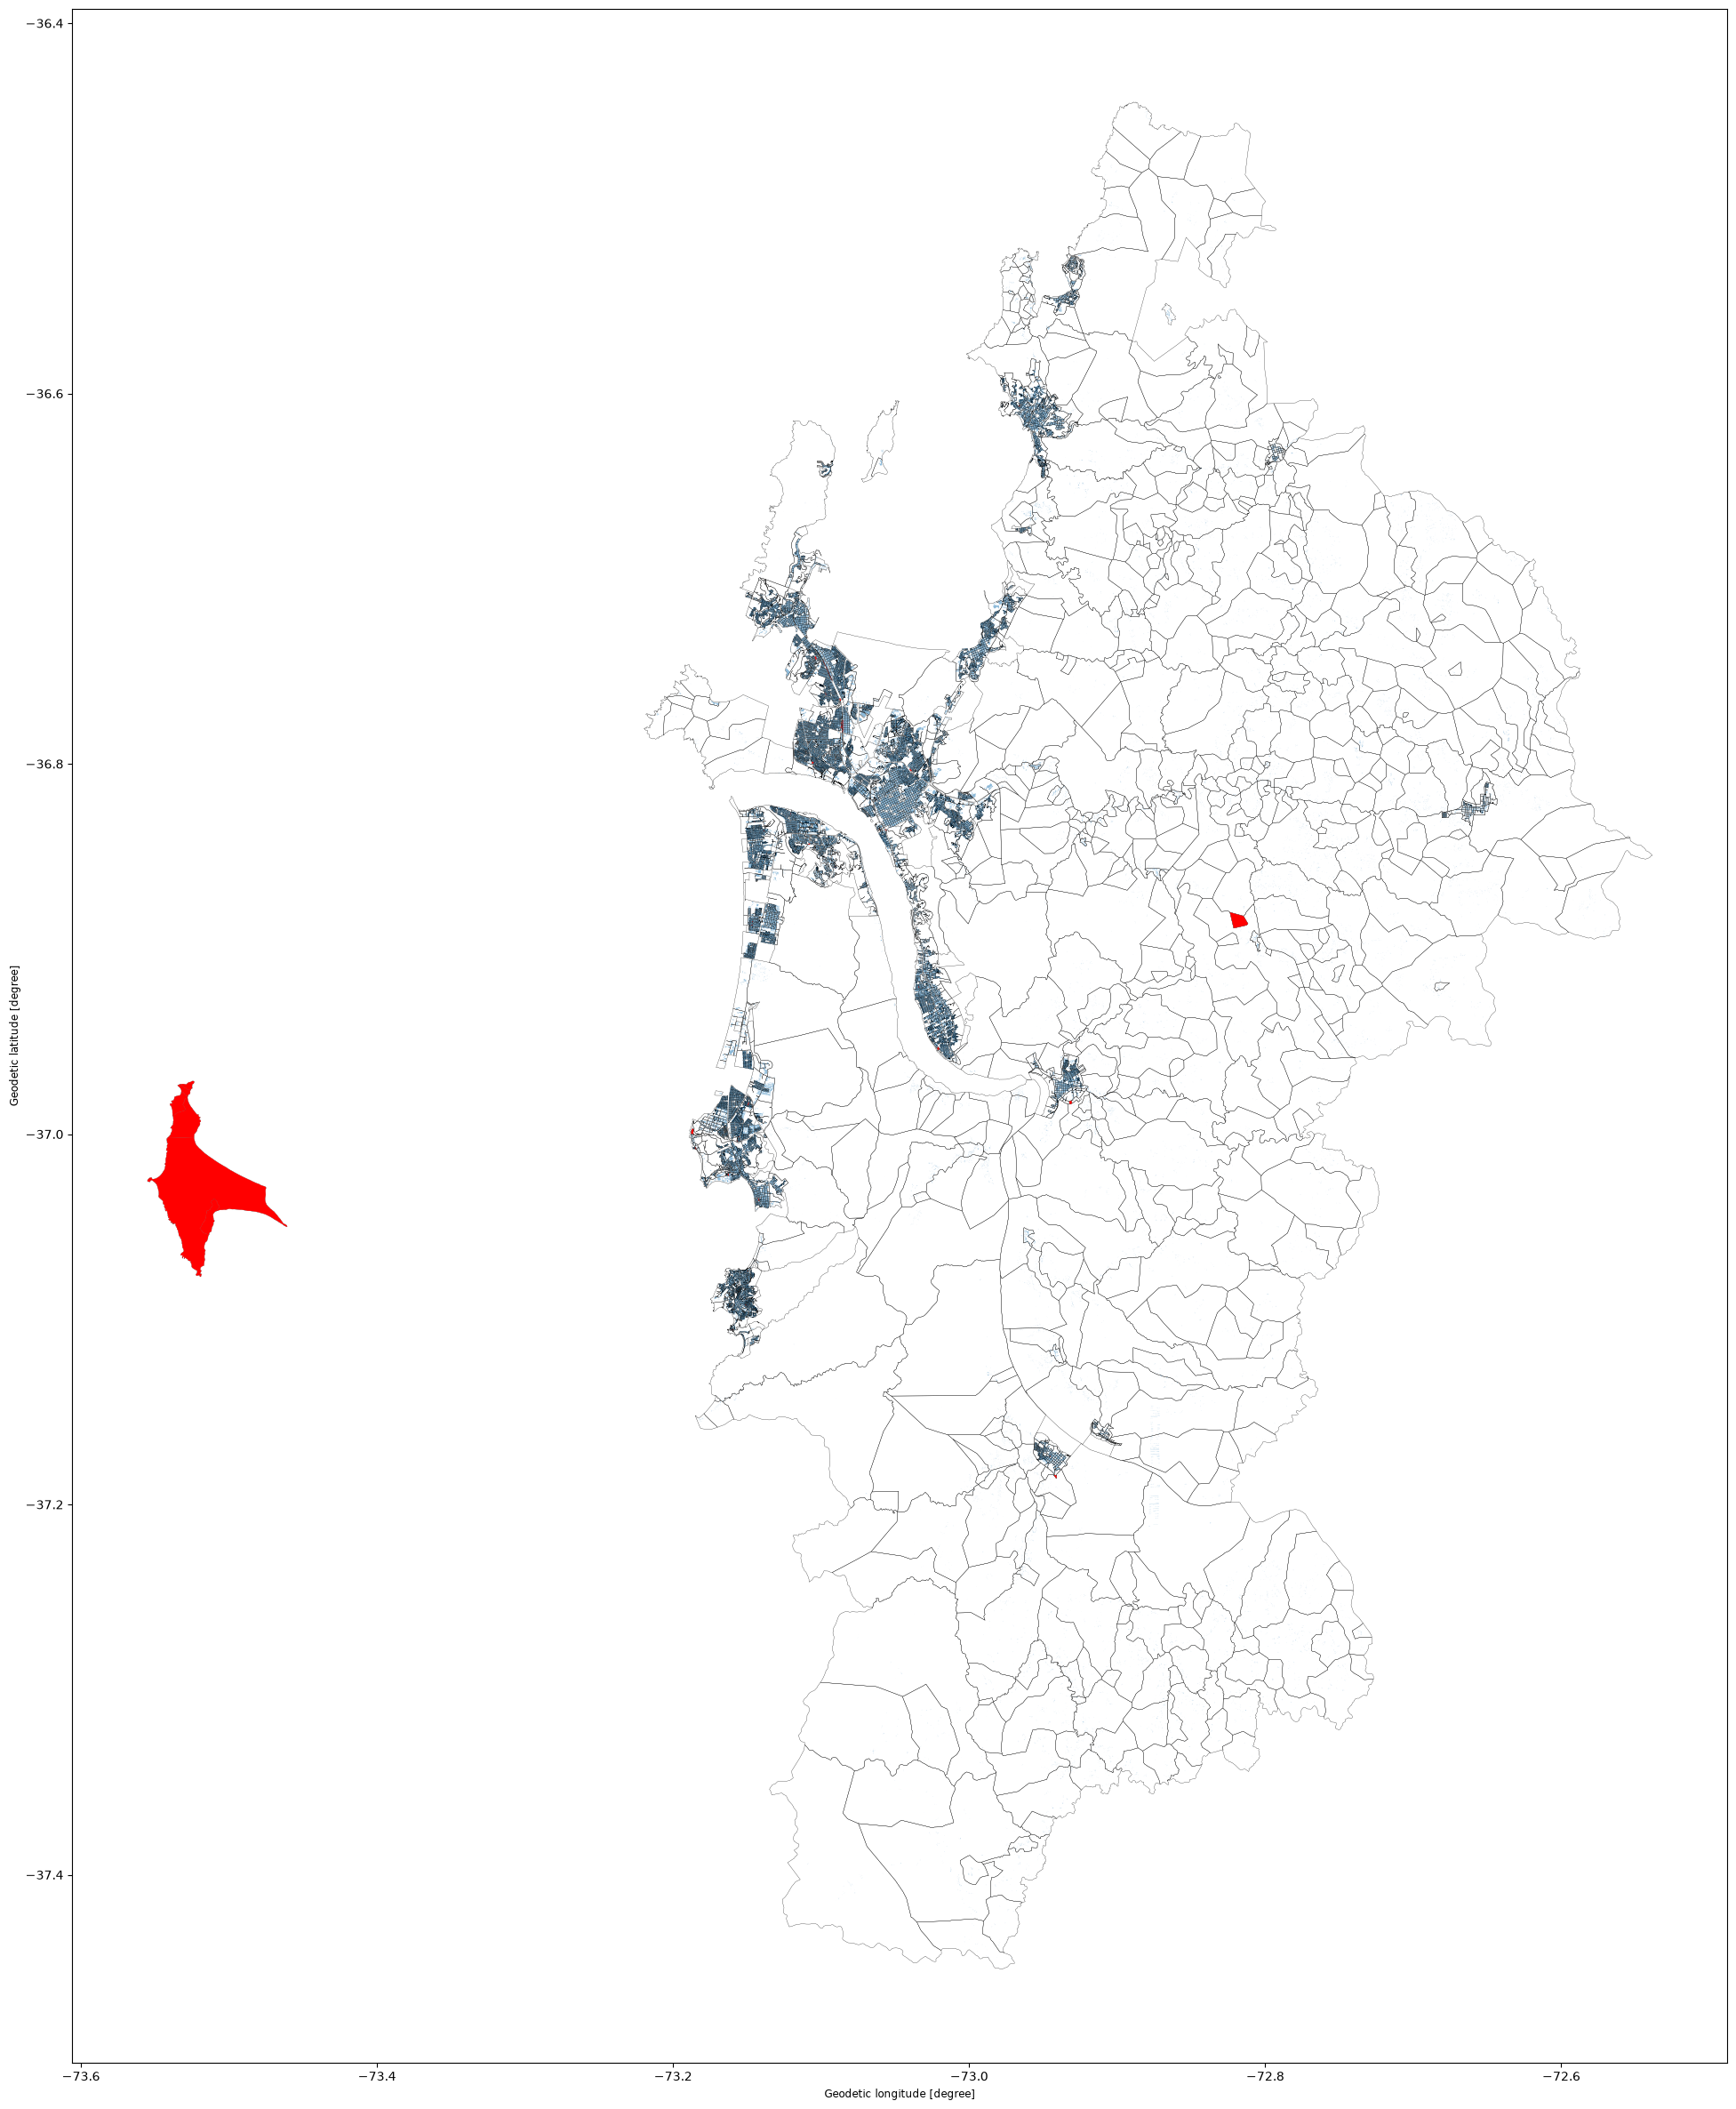

In [8]:
ax = blocks.plot(figsize=(30, 30), color="none", edgecolor="black", linewidth=0.2)
building_blocks[building_blocks["area"] > 1000].plot(ax=ax, alpha=0.5)
blocks[~blocks.id_manzent.isin(buildings.id_manzent.unique())].plot(ax=ax, color="red")

In [ ]:
import numpy as np

# one point per housing unit: the units of each block are spaced uniformly along the
# outlines of its building hulls. Blocks without buildings get a made-up polygon: the
# census block shrunk by INSET metres (less if that would make it disappear)
INSET = 5  # metres

housing_units = pd.read_parquet("data/output/housingunits_manzent.parquet")
no_block = ~housing_units.id_manzent.isin(blocks.id_manzent)
print(
    f"units without a block polygon (not located): {no_block.sum()}"
    f" ({housing_units.id_manzent.isna().sum()} with no id_manzent)"
)
housing_units = housing_units[~no_block]
housing_units["id_manzent"] = housing_units.id_manzent.astype(int)

block_geoms_m = blocks.set_index("id_manzent").geometry.to_crs(metric_crs)
inner = block_geoms_m.buffer(-INSET)
inset = INSET
while inner.is_empty.any() and inset > 0.5:
    inset /= 2
    empty = inner.is_empty
    inner[empty] = block_geoms_m[empty].buffer(-inset)
inner[inner.is_empty] = block_geoms_m[inner.is_empty]  # too thin for any inset

hull_outlines = building_blocks.set_index("id_manzent").geometry.to_crs(metric_crs).boundary
lines = np.asarray(hull_outlines.reindex(housing_units.id_manzent).values)
no_hull = shapely.is_missing(lines)
lines[no_hull] = np.asarray(inner.boundary.reindex(housing_units.id_manzent[no_hull]).values)

# unit i of n sits at (i + 0.5) / n of the block's total outline length
by_block = housing_units.groupby("id_manzent")
position = (by_block.cumcount() + 0.5) / by_block.id_manzent.transform("size")
points = shapely.line_interpolate_point(lines, position.to_numpy(), normalized=True)

housing_units = gpd.GeoDataFrame(
    housing_units, geometry=points, crs=metric_crs
).to_crs(4326)
print(f"units placed: {len(housing_units)}, on inset block outline (no buildings): {no_hull.sum()}")
housing_units

units without a block polygon (not located): 3689 (1690 with no id_manzent)
units placed: 355997, on inset block outline (no buildings): 947


,id_zona,viviendas,viviendas_particulares,viviendas_colectivas,viviendas_particulares_ocupadas,tipo_vivienda_casa,tipo_vivienda_depto,tipo_vivienda_ruka,tipo_vivienda_pieza,tipo_vivienda_mediagua,...,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo,id_manzent,on_hull,geometry
0,30,1,1,0,1,1,0,0,0,0,...,1.0,1.0,0.0,2.0,0.0,0.0,0.0,8103011001010,True,POINT (-73.02967 -36.90244)
1,30,1,1,0,1,1,0,0,0,0,...,2.0,0.0,2.0,2.0,0.0,0.0,0.0,8103011001002,True,POINT (-73.03435 -36.89287)
2,30,1,1,0,1,1,0,0,0,0,...,1.0,0.0,0.0,1.0,1.0,2.0,0.0,8103011001010,True,POINT (-73.02987 -36.90242)
3,30,1,1,0,1,0,1,0,0,0,...,2.0,1.0,0.0,2.0,0.0,0.0,0.0,8103011001010,True,POINT (-73.02995 -36.90227)
4,30,1,1,0,1,0,1,0,0,0,...,1.0,0.0,0.0,2.0,0.0,0.0,0.0,8103011001010,True,POINT (-73.0299 -36.90214)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
359681,16049,1,1,0,1,1,0,0,0,0,...,3.0,1.0,1.0,3.0,0.0,0.0,0.0,8111102014065,True,POINT (-72.86797 -36.6973)
359682,16049,1,1,0,1,1,0,0,0,0,...,1.0,0.0,1.0,2.0,0.0,0.0,0.0,8111102014063,True,POINT (-72.8636 -36.67906)
359683,16049,1,1,0,1,1,0,0,0,0,...,1.0,0.0,0.0,2.0,0.0,0.0,0.0,8111102014063,True,POINT (-72.87447 -36.67885)
359684,16049,1,1,0,1,1,0,0,0,0,...,3.0,0.0,2.0,2.0,0.0,0.0,0.0,8111102014066,True,POINT (-72.86278 -36.67572)


In [24]:
housing_units = housing_units.merge(blocks[["id_manzent", "tipo"]], "left", "id_manzent")

In [10]:
# block ids that housing units were assigned to but have no polygon in the shapefile
units_all = pd.read_parquet("data/output/housingunits_manzent.parquet")
missing = units_all[units_all.id_manzent.notna() & ~units_all.id_manzent.isin(blocks.id_manzent)]
missing_blocks = (
    missing.assign(id_manzent=missing.id_manzent.astype(int))
    .groupby(["id_zona", "id_manzent"])
    .size()
    .rename("housing_units")
    .reset_index()
)
print(f"{len(missing_blocks)} block ids without polygon, {len(missing)} housing units, {missing_blocks.id_zona.nunique()} zones")
missing_blocks

17 block ids without polygon, 1999 housing units, 17 zones


,id_zona,id_manzent,housing_units
0,2421,8101991999999,228
1,3534,8102991999999,333
2,3746,8108991999999,61
3,4333,8105991999999,24
4,5142,8103991999999,100
5,5507,8110081004999,32
6,5840,8106991999999,59
7,7079,8111991999999,100
8,8674,8107991999999,74
9,8915,8102031001999,422


In [28]:
housing_units.to_parquet("data/output/geo_housingunits_manzent.parquet")

In [12]:
gdf = gpd.read_file("data/poblacion_sintetica/hogares_geo_v1.shp")
gdf = gdf[gdf.ID_MANZENT.isin(blocks.id_manzent.unique())]

# aggregate housingunits
gdf = gdf.assign(
    HOGARES = 1
)

gdf = gdf.drop(columns=[
    # "id_hogar",
    # "tipo_hogar",
    # "tipo_operativo"
    "INDICES"
])

gdf = gdf.groupby(["ID_ZONA_LO", "ID_MANZENT", "NVIV"])
gdf = gdf.agg({
    "HOGARES": "sum",
    "HOMBRES": "sum",
    "MUJERES": "sum",
    "EDAD_0A5": "sum",
    "EDAD_6A14": "sum",
    "EDAD_15A64": "sum",
    "EDAD_65YMA": "sum",
    "CASA": "first",
    "DEPTO": "first",
    "geometry": "first"
})
gdf = gdf.reset_index()

gdf = gdf.groupby(["ID_ZONA_LO", "ID_MANZENT", "NVIV"])
gdf = gdf.agg({
    "HOGARES": "sum",
    "HOMBRES": "sum",
    "MUJERES": "sum",
    "EDAD_0A5": "sum",
    "EDAD_6A14": "sum",
    "EDAD_15A64": "sum",
    "EDAD_65YMA": "sum",
    "CASA": "first",
    "DEPTO": "first",
    "geometry": "first"
})
gdf = gdf.reset_index()
# gdf = gdf.merge(blocks.set_index("id_manzent")[["geometry"]], "left", left_on="ID_MANZENT", right_index=True)
# gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs=4326)

gdf["PERSONAS"] = gdf.HOMBRES + gdf.MUJERES
gdf = gdf.rename(columns={
    "ID_ZONA_LO": "id_zona",
    "ID_MANZENT": "id_manzent",
    "NVIV": "id_vivienda",
    "VIVIENDAS": "viviendas",
    "HOGARES": "hogares",
    "HOMBRES": "hombres",
    "MUJERES": "mujeres",
    "EDAD_0A5": "edad_0a5",
    "EDAD_6A14": "edad_6a14",
    "EDAD_15A64": "edad_15a64",
    "EDAD_65YMA": "edad_65ymas",
    "CASA": "tipo_vivienda_casa",
    "DEPTO": "tipo_vivienda_depto",
    "PERSONAS": "personas"
})

gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs=4326)
gdf

,id_zona,id_manzent,id_vivienda,hogares,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,tipo_vivienda_casa,tipo_vivienda_depto,geometry,personas
0,30,8103011001001,1,1,2,1,1,0,2,0,1,0,POINT (-73.03797 -36.88898),3
1,30,8103011001001,3,1,1,1,0,0,1,1,1,0,POINT (-73.03624 -36.89224),2
2,30,8103011001001,7,1,1,1,0,0,2,0,1,0,POINT (-73.03466 -36.89658),2
3,30,8103011001001,9,1,1,0,0,0,1,0,1,0,POINT (-73.03465 -36.89429),1
4,30,8103011001002,278,1,1,2,1,1,1,0,0,1,POINT (-73.02988 -36.88535),3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256011,15930,8101151004901,558,1,1,3,0,0,2,2,1,0,POINT (-73.054 -36.8061),4
256012,15930,8101151004901,560,1,0,1,0,0,0,1,1,0,POINT (-73.05397 -36.80604),1
256013,15930,8101151004901,626,1,1,1,0,0,2,0,1,0,POINT (-73.05389 -36.8053),2
256014,15930,8101151004901,634,1,1,0,0,0,0,1,1,0,POINT (-73.05374 -36.80713),1


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

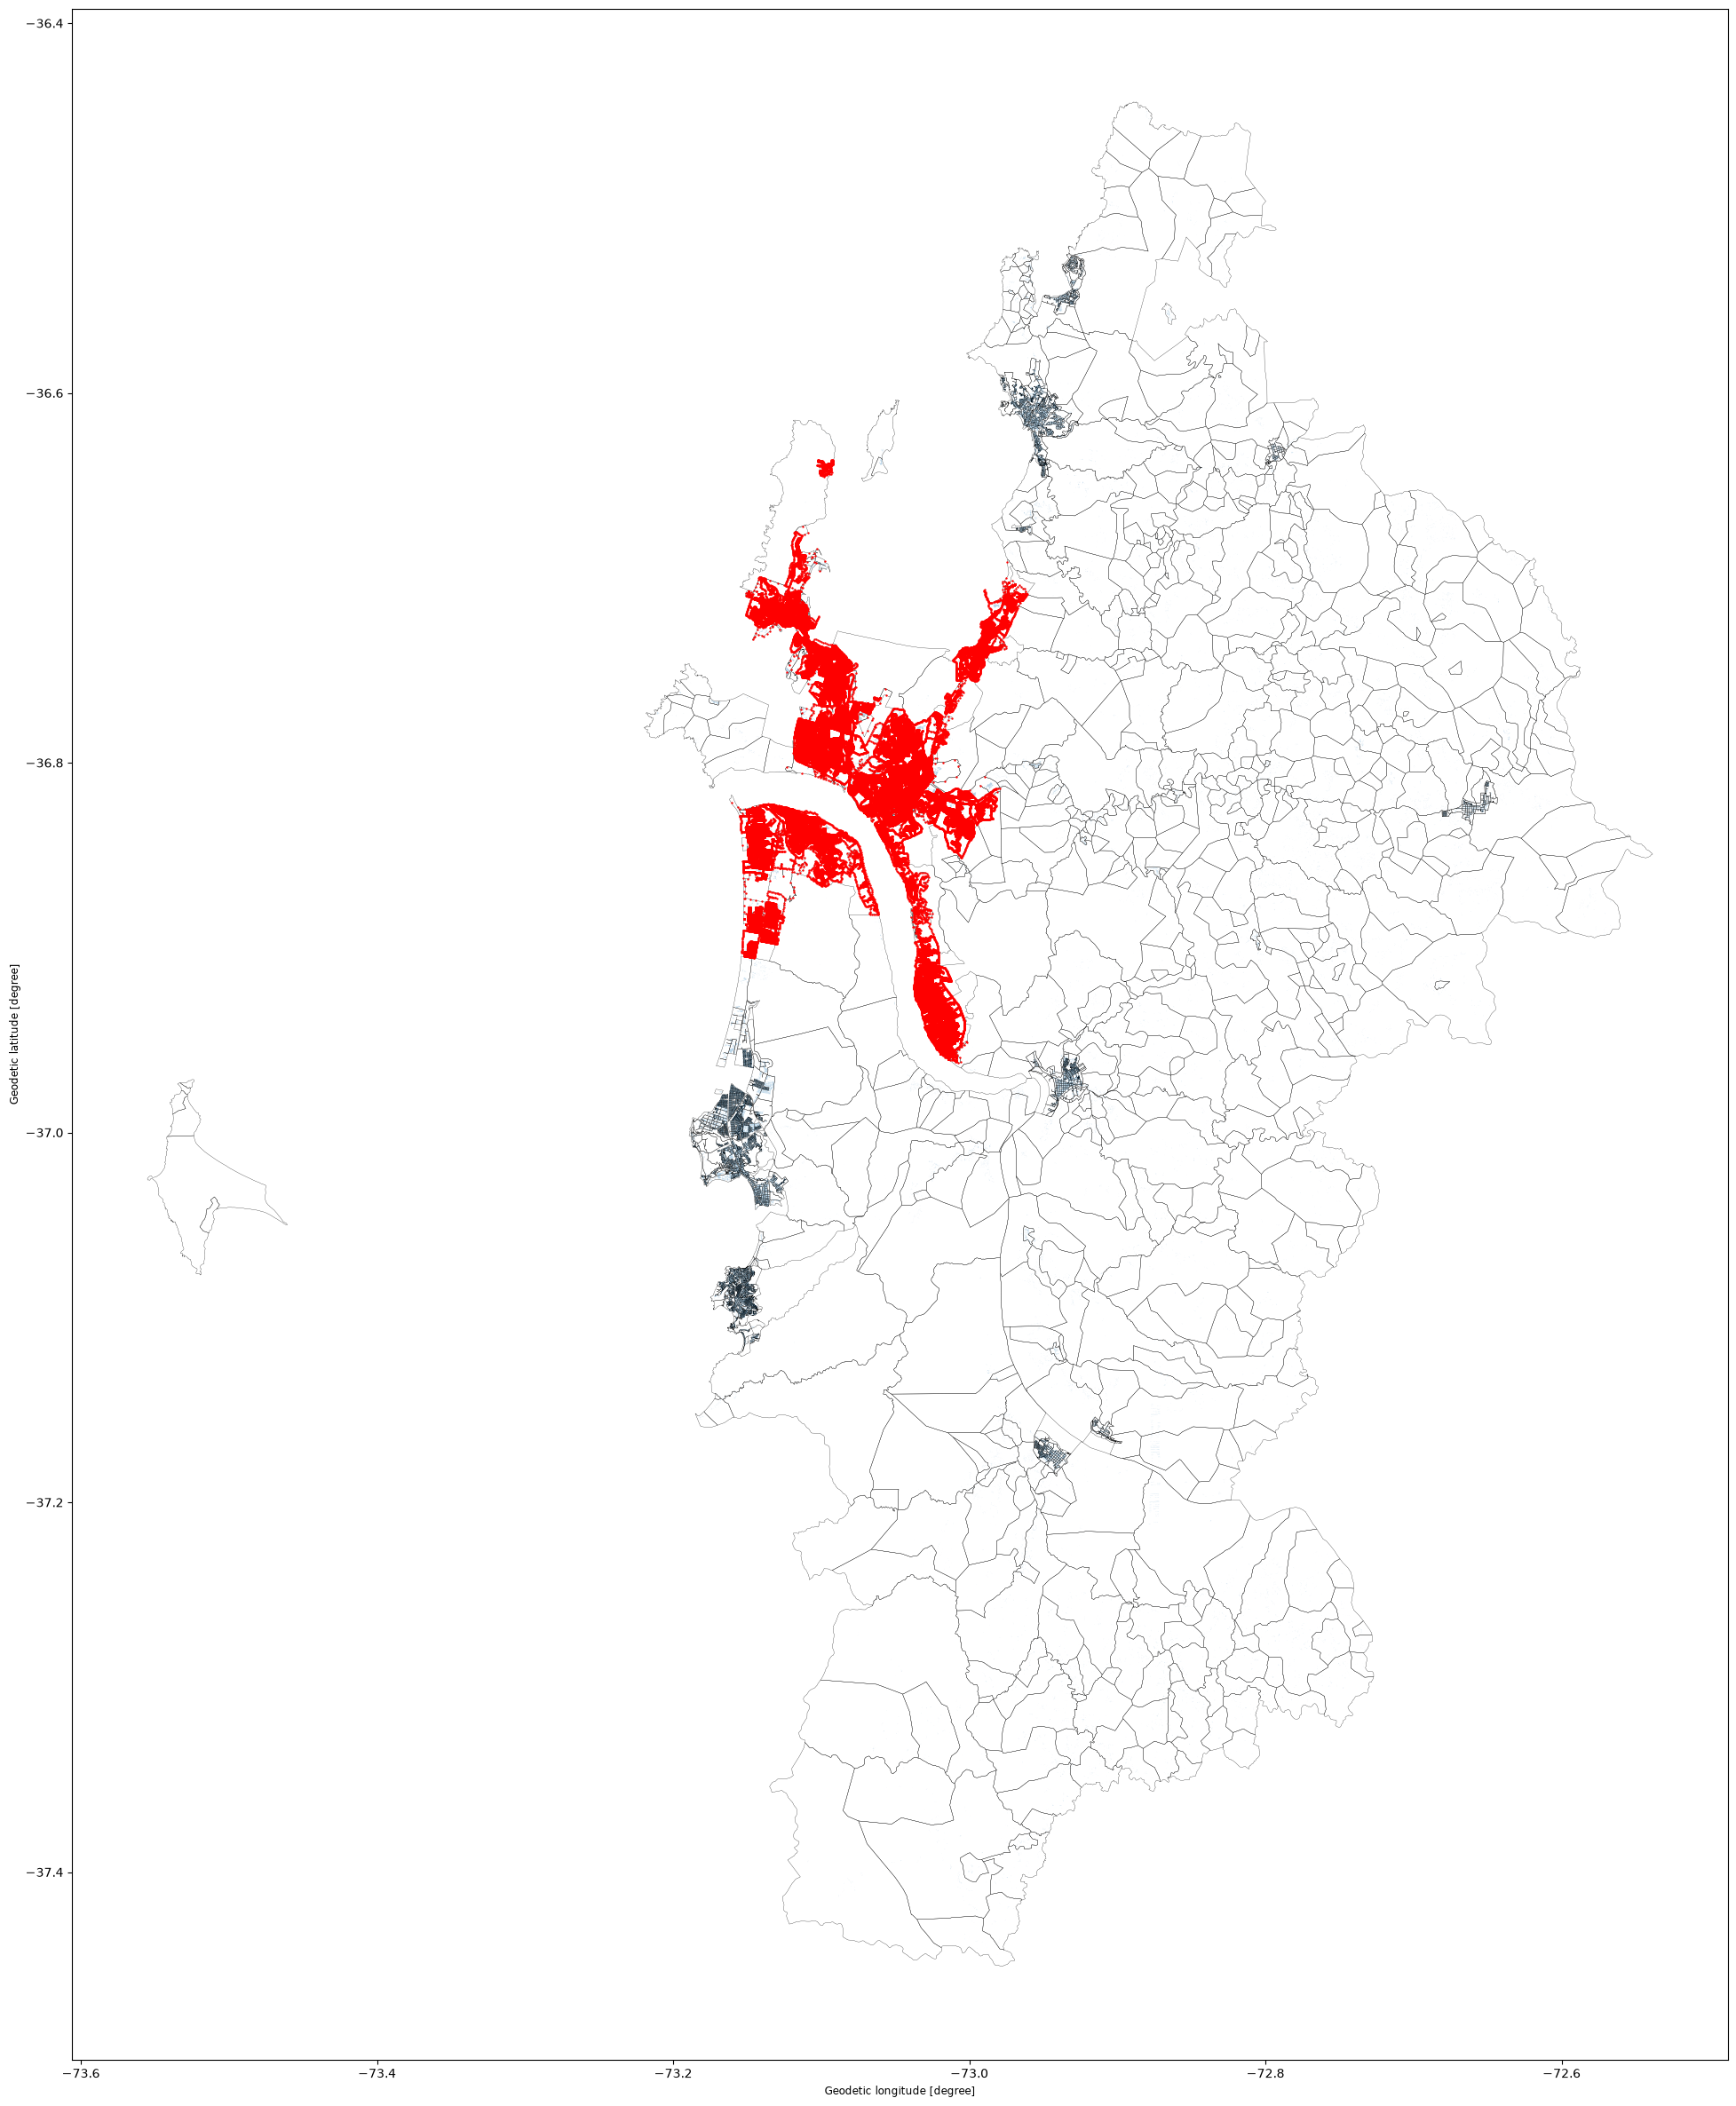

In [13]:
ax = blocks.plot(figsize=(30, 30), color="none", edgecolor="black", linewidth=0.2)
building_blocks.plot(ax=ax, alpha=0.3)
gdf.plot(ax=ax, markersize=0.5, color="red")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

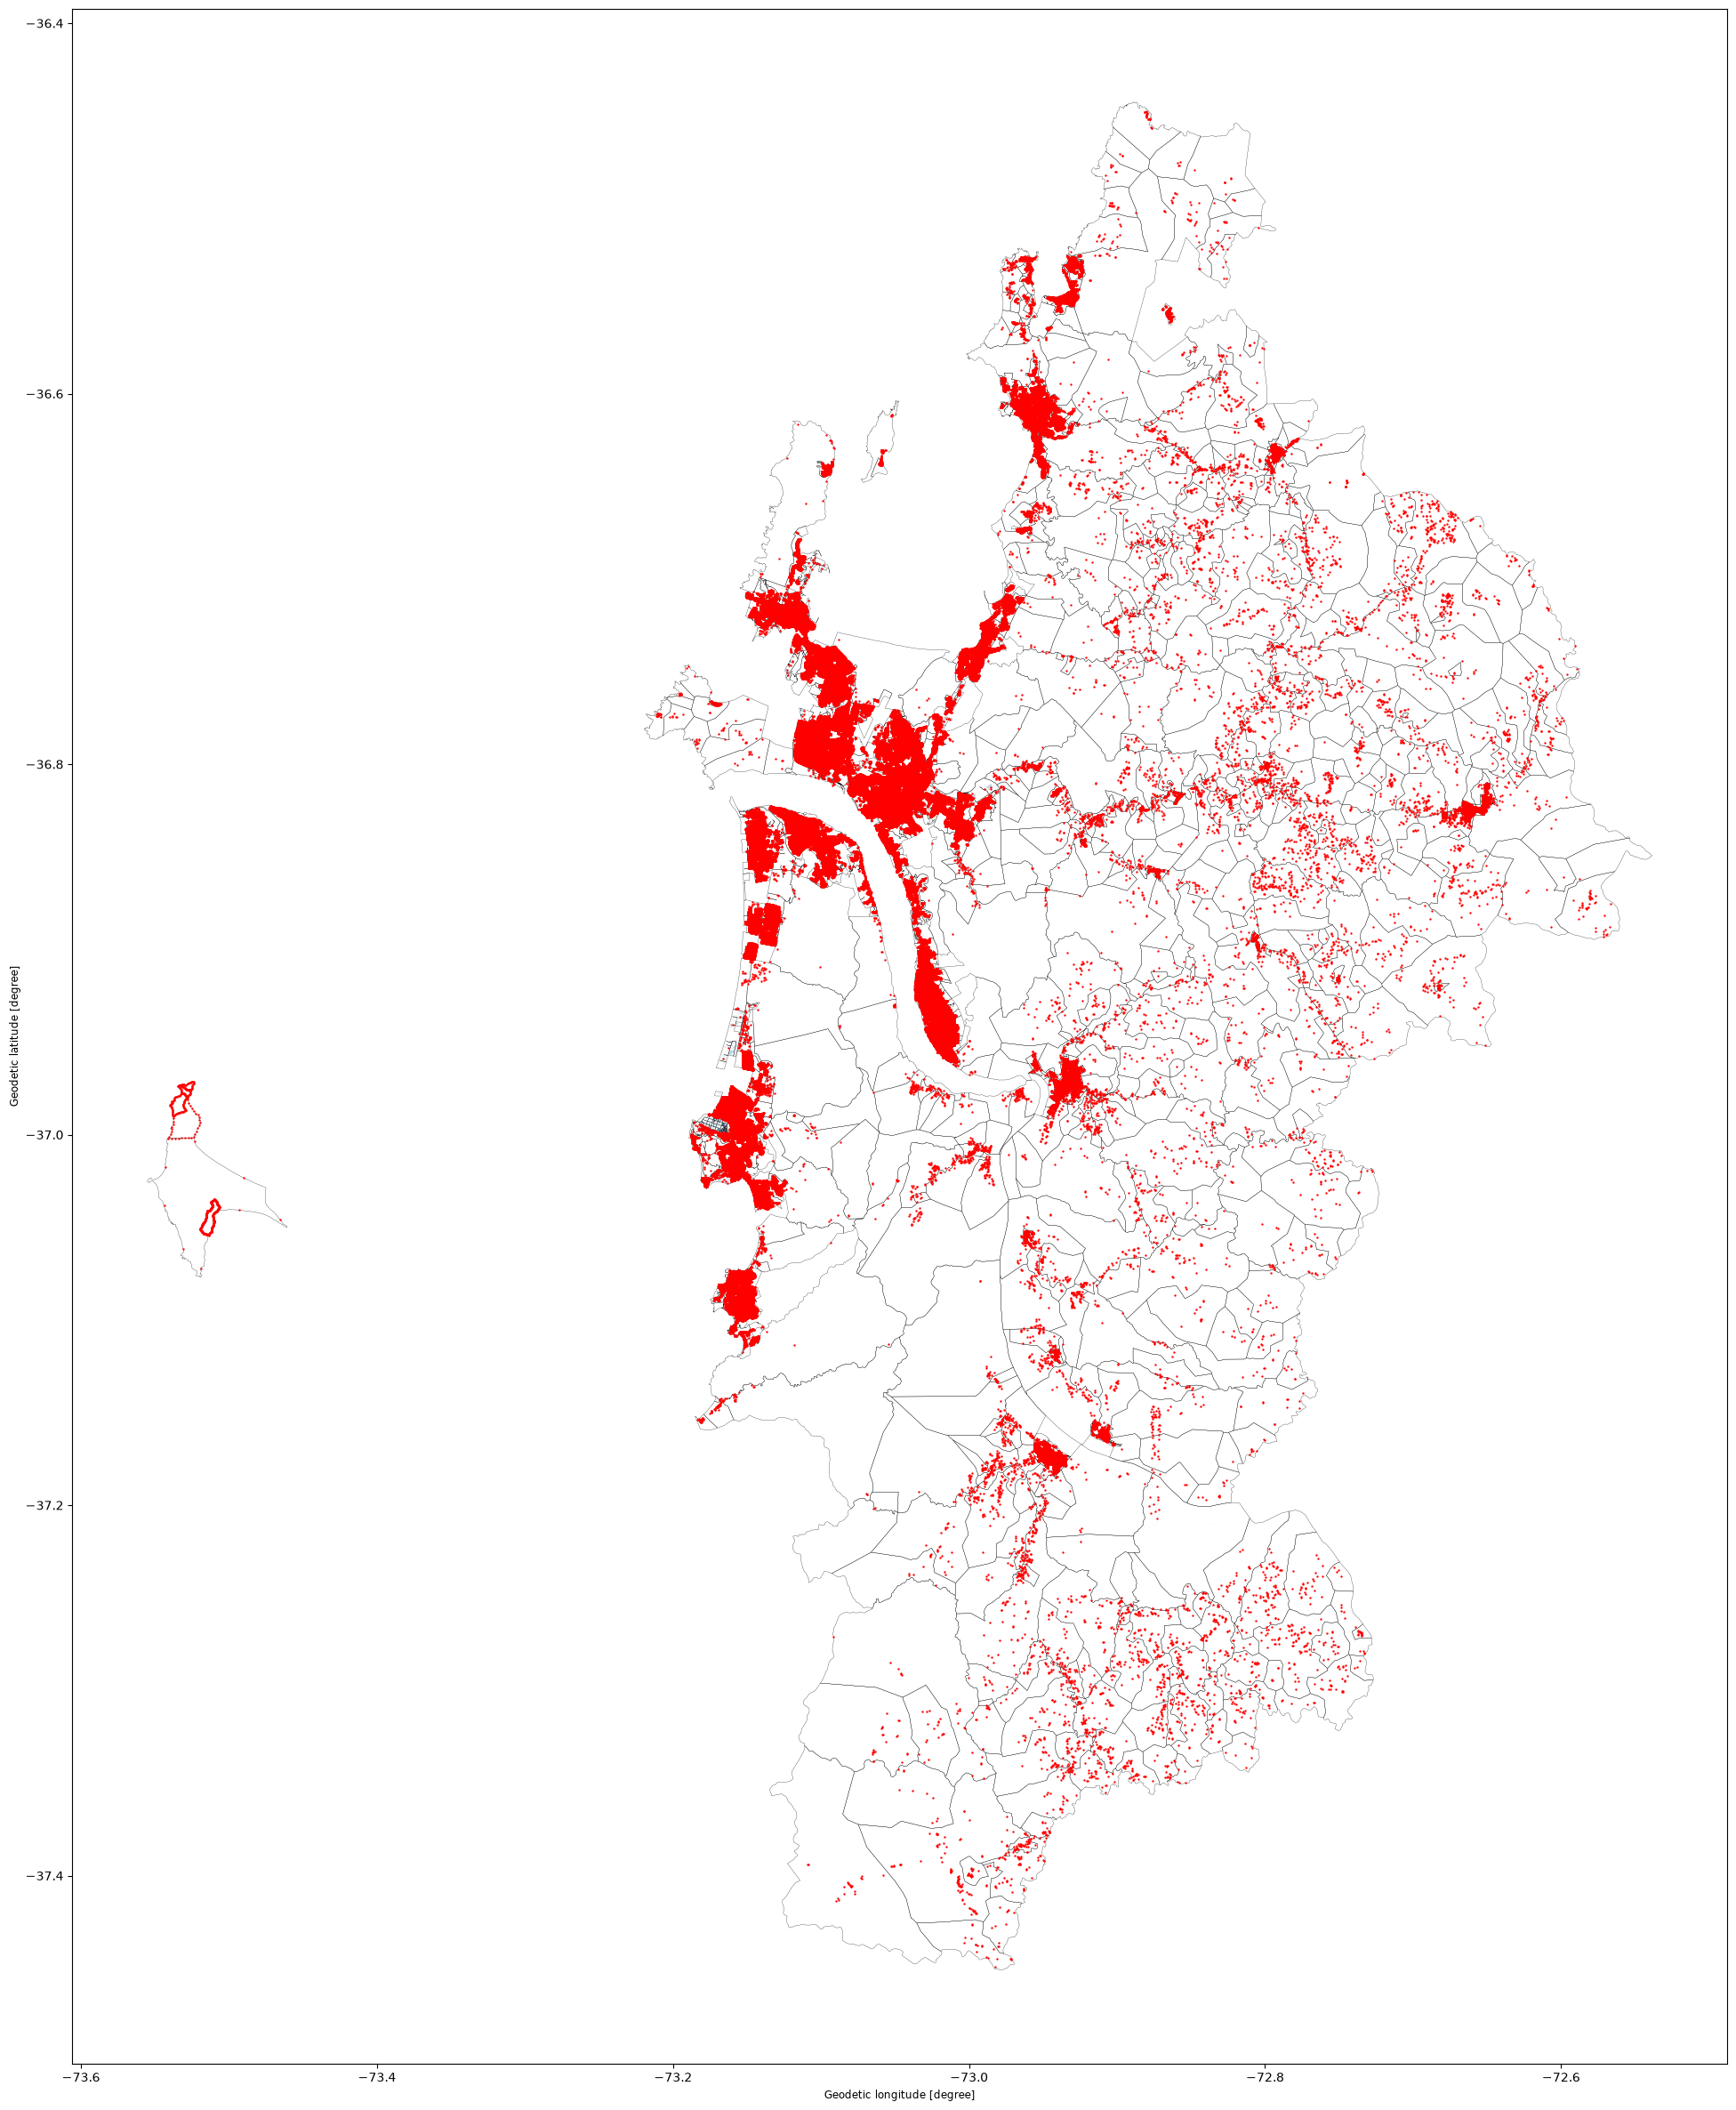

In [14]:
ax = blocks.plot(figsize=(30, 30), color="none", edgecolor="black", linewidth=0.2)
building_blocks.plot(ax=ax, alpha=0.3)
housing_units.plot(ax=ax, markersize=0.5, color="red")